# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [105]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np  
import pandas as pd 
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [106]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [107]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [108]:
# TODO: muestra los nombres de las columnas
df.columns
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [109]:
# TODO: consulta los tipos de datos

print(df.dtypes) # me sale nombre de la columna y su tipo

# df.dtypes  Esto me devuelve un objeto que tiene k:v
#for t in df.dtypes: # me sale solo los tipos
#    print(t)

print("/////////////////")
for columna, tipo in df.dtypes.items(): # Iteramos como un diccionario normal
    print(f"{columna} : {tipo}")

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object
/////////////////
cliente_id : int64
edad : int64
antiguedad_meses : float64
ingresos_anuales : float64
gasto_mensual : float64
num_compras : int64
devoluciones : int64
dispositivo : str
zona : str
nivel_fidelidad : str
satisfaccion : int64
compra_proximo_mes : str


In [110]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Responde

1. ¿Cuántas muestras contiene? 400
2. ¿Cuántas columnas? 12
3. ¿Cuál es la unidad de observación? El cliente
4. ¿Cuál es el identificador? cliente_id
5. ¿Cuál es el target? compra_proximo_mes
6. ¿Qué columnas tienen valores ausentes?
antiguedad_meses (tiene 395, faltan 5) ingresos_anuales (tiene 396, faltan 4) gasto_mensual (tiene 397, faltan 3)


# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [111]:
# TODO: muestra describe() para gasto_mensual
print(df['gasto_mensual'].describe())
print("//////")
#puedo acceder a elementos individuales por ejemplo
print(df['gasto_mensual'].describe()['count'])
print("//////")
print("Mediana: ", df['gasto_mensual'].median())
print("Q1: ", df['gasto_mensual'].quantile(.25))
print("Q2: ", df['gasto_mensual'].quantile(.5))
print("Q3: ", df['gasto_mensual'].quantile(.75))
# TODO: calcula las medidas necesarias


count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
//////
397.0
//////
Mediana:  61.17
Q1:  39.72
Q2:  61.17
Q3:  90.15


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69.089320 |
| Mediana | 61.170000 |
| Desviación estándar | 39.023238 |
| Mínimo | 5.770000 |
| Q1 | 39.720000 |
| Q2 | 61.170000 |
| Q3 | 90.150000 |
| Máximo | 260.000000 |

### Interpreta

1. ¿Coinciden exactamente media y mediana? No
2. ¿Cuál es mayor? La media
3. ¿Qué puede indicar esta diferencia sobre la distribución? Hay un sesgo positivo, hacia la derecha.
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central? entre Q1 y Q3 

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

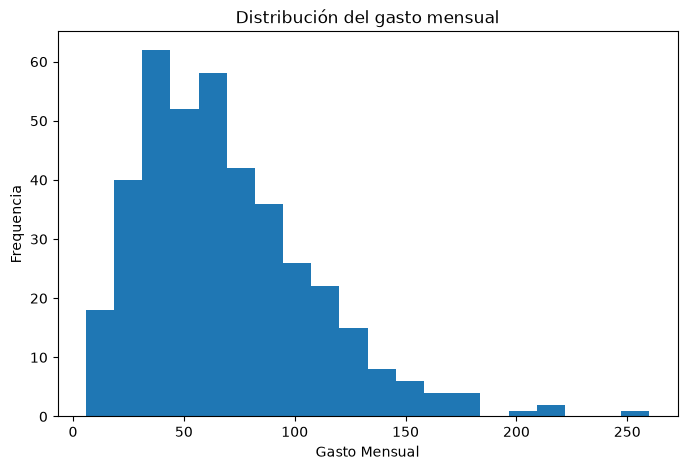

In [112]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df['gasto_mensual'].dropna(), bins = 20) #not a number / le estoy diciendo borra los NaN
plt.xlabel("Gasto Mensual")
plt.ylabel("Frequencia")
plt.title("Distribución del gasto mensual")
plt.show()

#Gráfico con asimetria positiva / sesgada hacia la derecha



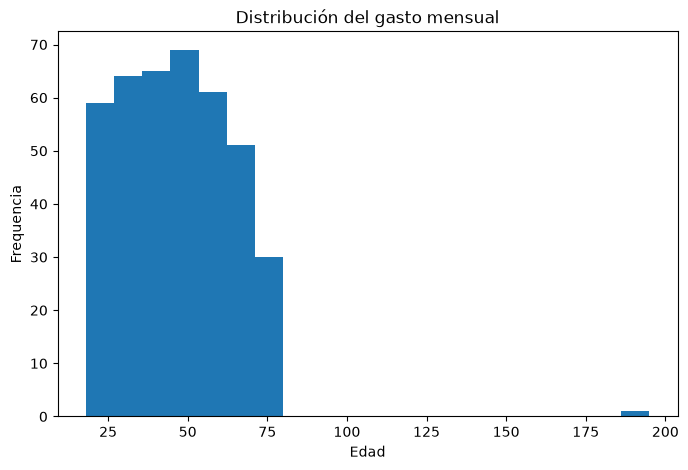

In [113]:
plt.figure(figsize=(8,5))
plt.hist(df['edad'].dropna(), bins = 20) #not a number / le estoy diciendo borra los NaN
plt.xlabel("Edad")
plt.ylabel("Frequencia") # SIEMPRE FREQUENCIA YA QUE ES LA CANTIDAD DE VECES QUE APARECE EL DATO
plt.title("Distribución del gasto mensual")
plt.show()

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes? Entre 25 y 110
2. ¿La distribución parece aproximadamente simétrica? No
3. ¿Existe una cola hacia valores altos o bajos? Hacia los valores altos a la derecha.
4. ¿Observas valores alejados del resto? Sí

--------------------------------------------

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

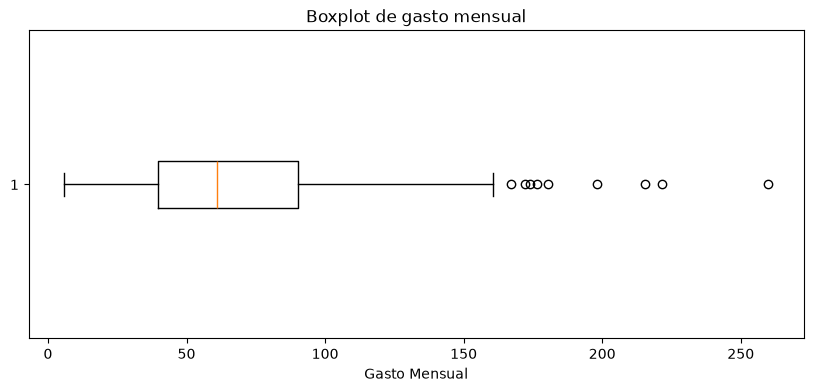

In [114]:
# TODO: crea un boxplot de gasto_mensual
plt.figure(figsize=(10,4))
plt.boxplot(df['gasto_mensual'].dropna(), orientation= 'horizontal') 
plt.xlabel("Gasto Mensual")
plt.title("Boxplot de gasto mensual")
plt.show()

In [115]:
#Todo lo qye hay a partir de le derecha son todos los resultados atípicos a partir del máximo (la línea sola de la derecha)
#Línea sola de la izquierda valor mínimo dentro de los valores Típicos
#El Cuantil 1 (valores debajo del 25 por ciento)
#El Cuantil 2 Línea naranja
#El Cuantil 3 (valores debajo del 75 por ciento)
# Los cuantiles me sirven para saber el valor de IQR

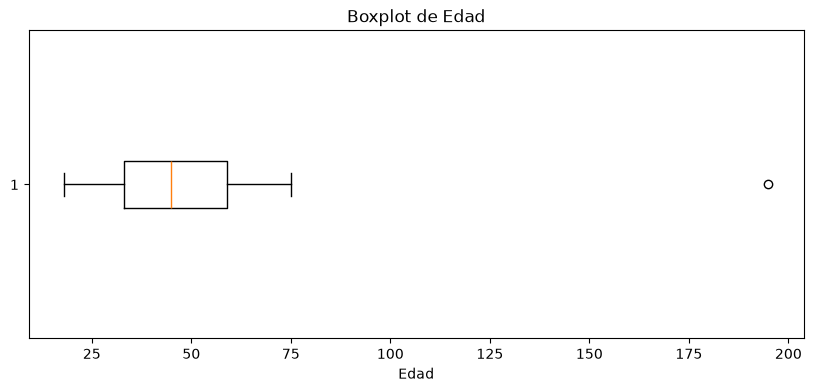

IQR : 26.00, Linferior: -6.00, Lsuperior: 98.00 


In [116]:
plt.figure(figsize=(10,4))
plt.boxplot(df['edad'].dropna(), orientation= 'horizontal') 
plt.xlabel("Edad")
plt.title("Boxplot de Edad")
plt.show()

Q1= df['edad'].quantile(.25)
Q2= df['edad'].quantile(.5)
Q3= df['edad'].quantile(.75)

# RANGO INTERCUNTILICO
IQR = Q3 - Q1

# TODO: calcula los límites inferior y superior
l_inf = Q1 - 1.5*IQR
l_sup = Q3 + 1.5*IQR

# TODO: muestra los resultados
print(f"IQR : {IQR:.2f}, Linferior: {l_inf:.2f}, Lsuperior: {l_sup:.2f} ")

### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?  61
2. ¿Observas posibles outliers? Sí, entre 165 y 180, otros dos de 200 y 220, y uno más en 260
3. ¿Aparecen principalmente por encima o por debajo?  Solo hacia arriba
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica. No, ya que el gráfico solo muestra que son valores matemáticamente inusuales. Para confirmar un error, se deberia de mirar la fuente de datos.

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [117]:
# TODO: calcula Q1, Q3 e IQR
Q1= df['gasto_mensual'].quantile(.25)
Q2= df['gasto_mensual'].quantile(.5)
Q3= df['gasto_mensual'].quantile(.75)

# RANGO INTERCUNTILICO
IQR = Q3 - Q1

# TODO: calcula los límites inferior y superior
l_inf = Q1 - 1.5*IQR
l_sup = Q3 + 1.5*IQR

# TODO: muestra los resultados
print(f"IQR : {IQR:.2f}, Linferior: {l_inf:.2f}, Lsuperior: {l_sup:.2f} ")

IQR : 50.43, Linferior: -35.93, Lsuperior: 165.80 


In [118]:
# TODO: crea outliers_gasto
filtro =(df['gasto_mensual'] < l_inf) | (df['gasto_mensual'] > l_sup)
outliers_gasto = df[filtro]

# TODO: muestra los posibles outliers
outliers_gasto

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


### Responde

1. ¿Cuántos posibles outliers has encontrado?
2. ¿Qué porcentaje representan?
3. ¿Cuál es el mayor `gasto_mensual`?
4. ¿Eliminarías automáticamente estas observaciones?
5. ¿Qué investigarías antes?

**Respuesta:**  
Escribe aquí.

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [119]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
print(df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].describe())


             edad  ingresos_anuales  gasto_mensual  num_compras  devoluciones
count  400.000000        396.000000     397.000000   400.000000    400.000000
mean    46.402500      36440.920379      69.089320     8.225000      1.225000
std     18.007809      14325.228166      39.023238     2.780955      1.136929
min     18.000000       9000.000000       5.770000     2.000000      0.000000
25%     33.000000      26034.092500      39.720000     6.000000      0.000000
50%     45.000000      36817.275000      61.170000     8.000000      1.000000
75%     59.000000      45969.032500      90.150000    10.000000      2.000000
max    195.000000      82925.370000     260.000000    17.000000      5.000000


In [120]:
# TODO: calcula sus medianas
print(df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].median())

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64


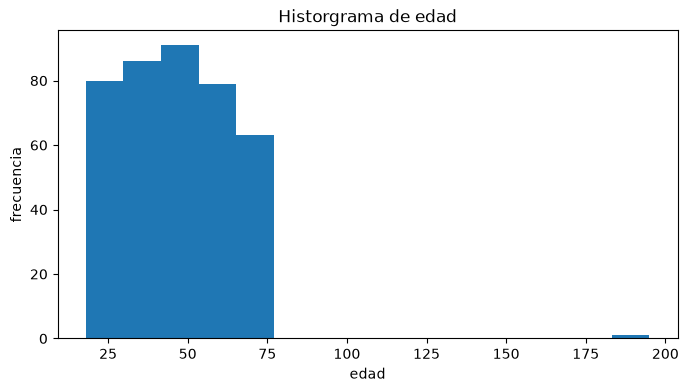

In [121]:
# TODO: histograma de edad
plt.figure(figsize=(8,4))
plt.hist(df["edad"].dropna(), bins=15)
plt.xlabel("edad")
plt.ylabel("frecuencia")
plt.title("Historgrama de edad")
plt.show()

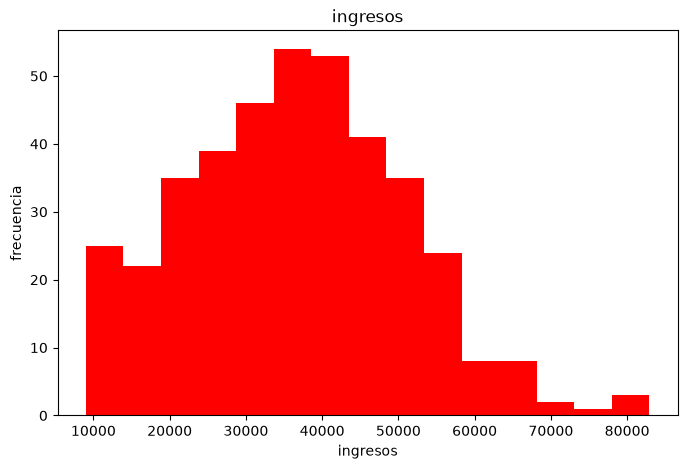

In [122]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8,5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15, color="red")
plt.xlabel("ingresos")
plt.ylabel("frecuencia") 
plt.title("ingresos")
plt.show()

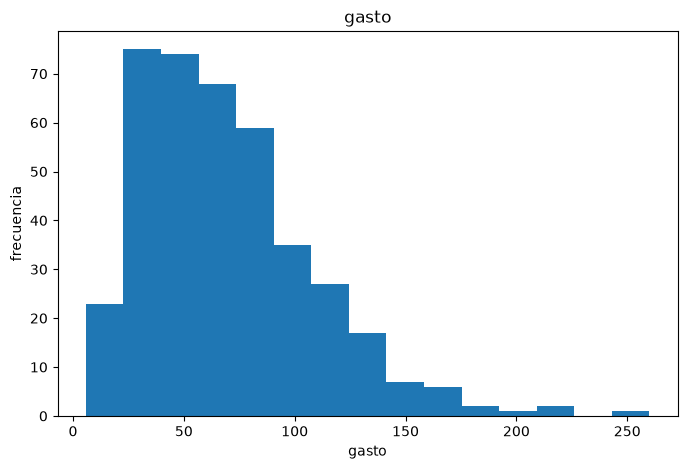

In [123]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df["gasto_mensual"].dropna(), bins=15)
plt.xlabel("gasto")
plt.ylabel("frecuencia")
plt.title("gasto")
plt.show()

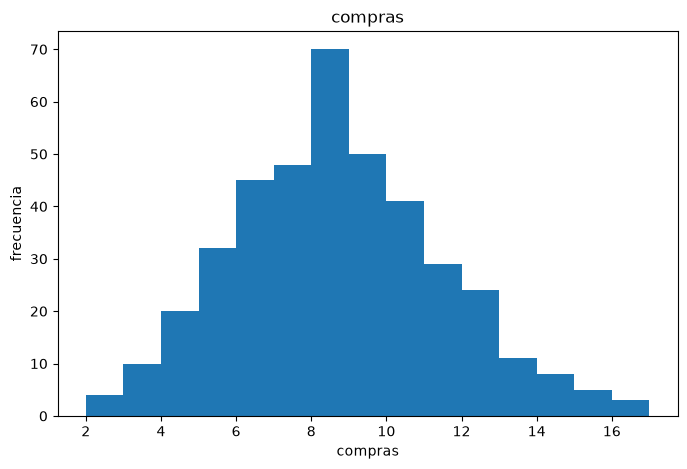

In [124]:
# TODO: histograma de num_compras
plt.figure(figsize=(8,5))
plt.hist(df["num_compras"].dropna(), bins=15)
plt.xlabel("compras")
plt.ylabel("frecuencia")
plt.title("compras")
plt.show()

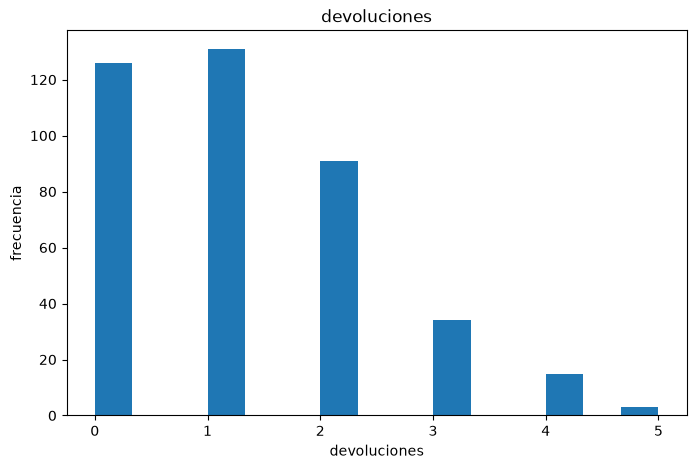

In [125]:
# TODO: histograma de devoluciones
# TODO: histograma de devoluciones
plt.figure(figsize=(8,5))
plt.hist(df["devoluciones"].dropna(), bins=15)
plt.xlabel("devoluciones")
plt.ylabel("frecuencia")
plt.title("devoluciones")
plt.show()

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46.40 | 45.00 | 18 | 195 | Máximo de 195 años: es imposible |
| ingresos_anuales | 36440.92 | 36817.28 | 9000.00 | 82925.37 | hay 4 nulos, 16 clientes con exactamente 9000, parece un valor mínimo impuesto.|
| gasto_mensual | 69.09 | 61.17 | 5.77 | 260.00 | hay 3 nulos, asimetría a la derecha (la media > la mediana) y 9 outliers por arriba. |
| num_compras | 8.23 | 8.00 | 2 | 17 | Se distribuye de forma igual (simetrica) |
| devoluciones | 1.23 | 1.00 | 0 | 5 | Valores bajos y discretos, muchos clientes con 0 devoluciones. |

### Busca una observación sospechosa

- ¿Qué variable es? Edad
- ¿Qué valor tiene? 195 años
- ¿Por qué parece sospechoso? No es lógico que una persona sea tan vieja
- ¿Es un outlier? Sí
- ¿Podemos afirmar directamente que es un error? Aunque sea muy raro que alguien tenga 195 años se tendría que justificar con datos, pero todo apunta a que es un error.
- ¿Qué harías antes de modificarlo? Revisar el resto de datos para ver que no haya casos parecidos.


# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [126]:
# TODO: analiza dispositivo
print(df["dispositivo"].value_counts())
print(df["dispositivo"].value_counts(normalize = True))
print(df["dispositivo"].value_counts(normalize = True)*100)

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64


In [127]:
# TODO: analiza zona
print(df["zona"].value_counts())
print(df["zona"].value_counts(normalize = True))
print(df["zona"].value_counts(normalize = True)*100)

zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64


In [128]:
# TODO: analiza nivel_fidelidad
print(df["nivel_fidelidad"].value_counts())
print(df["nivel_fidelidad"].value_counts(normalize = True))
print(df["nivel_fidelidad"].value_counts(normalize = True)*100)

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64


In [129]:
# TODO: analiza compra_proximo_mes
print(df["compra_proximo_mes"].value_counts())
print(df["compra_proximo_mes"].value_counts(normalize = True))
print(df["compra_proximo_mes"].value_counts(normalize = True)*100)

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    0.615
Sí    0.385
Name: proportion, dtype: float64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50 |
| zona | Este | 89 | 22.25 |
| nivel_fidelidad | Bronce | 162 | 40.50 |
| compra_proximo_mes | NO | 246 | 61.50 |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

Index(['Móvil', 'Ordenador', 'Tablet'], dtype='str', name='dispositivo')
[242 133  25]


Text(0, 0.5, 'Nº Clientes')

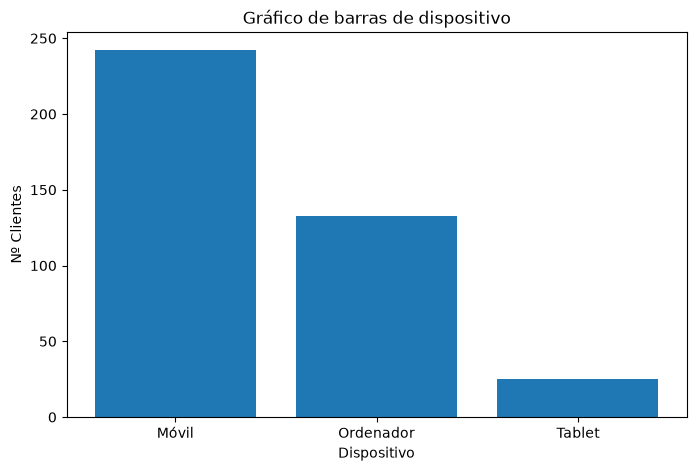

In [130]:
# TODO: gráfico de barras de dispositivo
conteos_disp = df['dispositivo'].value_counts()
print(conteos_disp.index)
print(conteos_disp.values)

plt.figure(figsize = (8, 5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.title("Gráfico de barras de dispositivo")
plt.xlabel("Dispositivo")
plt.ylabel("Nº Clientes")

Index(['Bronce', 'Plata', 'Oro', 'Platino'], dtype='str', name='nivel_fidelidad')


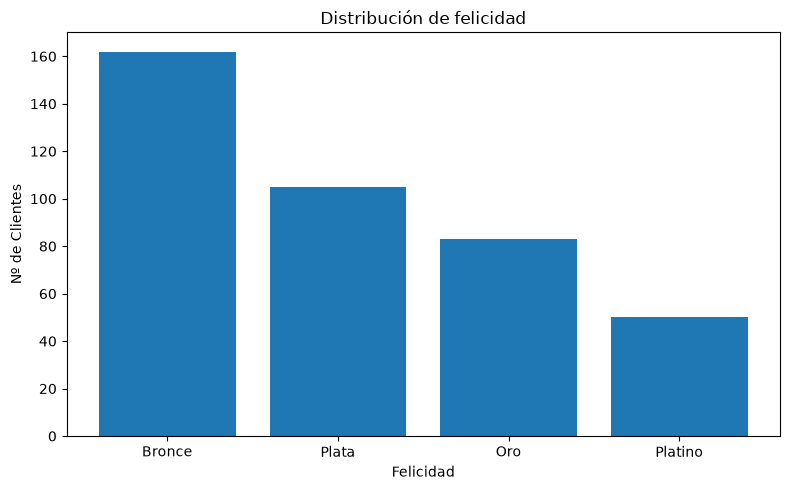

In [131]:
# TODO: gráfico de barras de nivel_fidelidad
conteosfidelidad = df["nivel_fidelidad"].value_counts()
print(conteosfidelidad.index)

plt.figure(figsize = (8, 5))
plt.bar(conteosfidelidad.index, conteosfidelidad.values)
plt.xlabel("Felicidad")
plt.ylabel("Nº de Clientes")
plt.title("Distribución de felicidad")
plt.tight_layout()
plt.show()

Index(['No', 'Sí'], dtype='str', name='compra_proximo_mes')


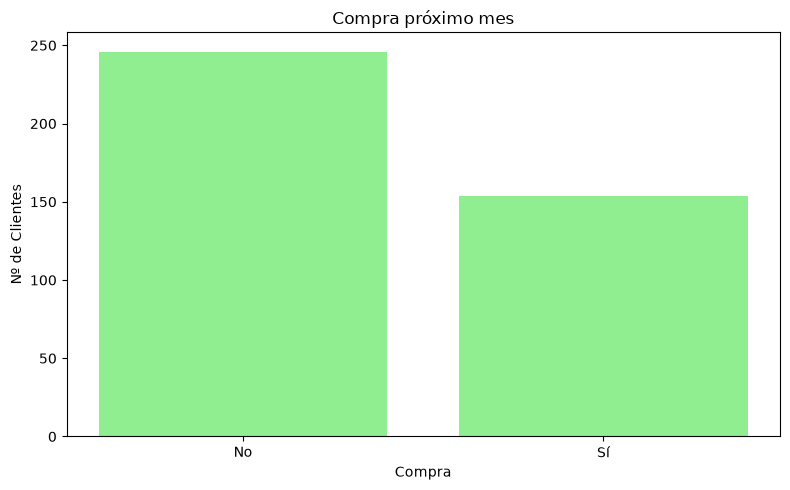

In [132]:
# TODO: gráfico de barras de compra_proximo_mes
conteoscompra_proximo_mes = df["compra_proximo_mes"].value_counts()
print(conteoscompra_proximo_mes.index)

plt.figure(figsize = (8, 5))
plt.bar(conteoscompra_proximo_mes.index, conteoscompra_proximo_mes.values, color = "Lightgreen")
plt.xlabel("Compra")
plt.ylabel("Nº de Clientes")
plt.title("Compra próximo mes")
plt.tight_layout()
plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.
- gráfico de barras de dispositivo = Claramente el móvil es más usado que el resto de dispositivos, y disminuye en cascada
- Distribución de felicidad = Aunque sea curioso, el nivel de felicidad se alza más en bronce (nível bajo) que en los que irian después
- Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas? 

Justifica utilizando porcentajes= No, claramente hay un desbalanze a favor de "No"


# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

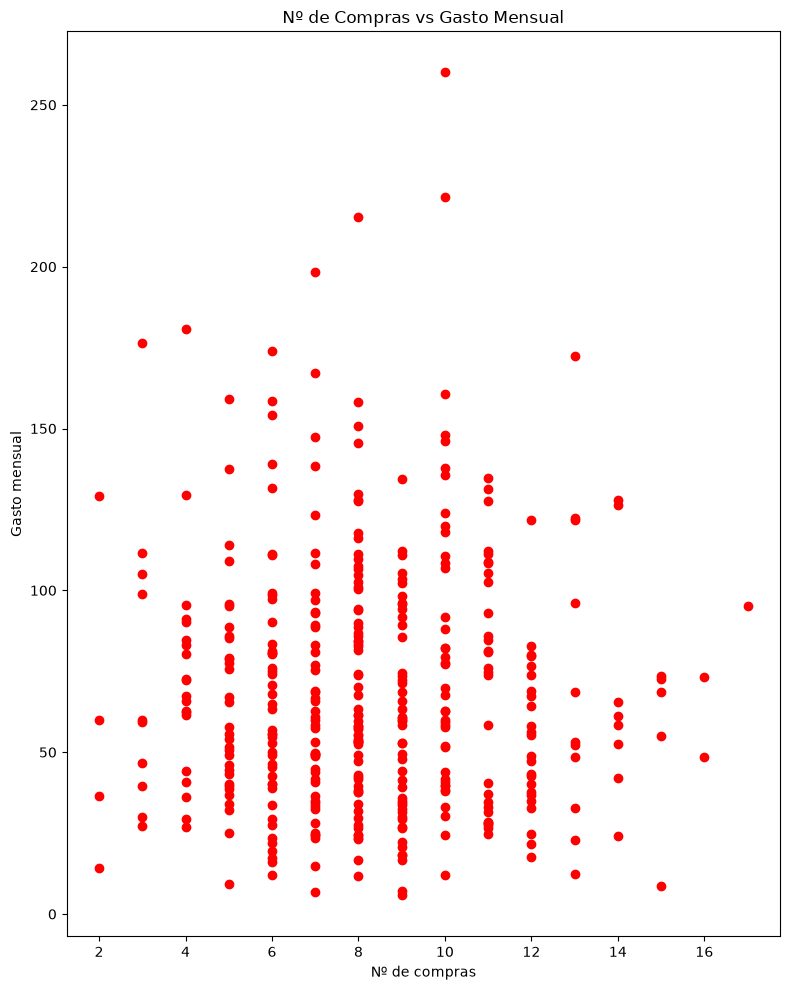

In [133]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.figure(figsize = (8, 10))
plt.scatter(df["num_compras"], df["gasto_mensual"], color = "red")
plt.xlabel("Nº de compras")
plt.ylabel("Gasto mensual")
plt.title("Nº de Compras vs Gasto Mensual")
plt.tight_layout()
plt.show()

### Antes de calcular la correlación

1. ¿Parece existir una relación? No
2. ¿Parece positiva o negativa? Realmente es neutra
3. ¿Parece fuerte o débil? débil
4. ¿Observas muestras especialmente alejadas? Sí.


# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [134]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
print(df["num_compras"].corr(df["gasto_mensual"]))
#Si el dato es muy proximo a    0   no hay correlación
#Si el dato cercano a           -1  es correlación negativa.
#Si el dato cercano a           1   es correlación positiva

-0.014165499001183279


### Interpreta

1. ¿Cuál es el valor de \(r\)?  -0.014165499001183279
2. ¿Es positivo o negativo? Negativo
3. ¿Qué significa el signo? Que la correlaciñon es neutra
4. ¿Coincide con lo observado en el scatter plot? Sí
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

No, el valor es próximo a cero (-0.01416...), lo que demuestra que no hay relación entre las variables


# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [135]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
numericas = df.select_dtypes(include="number").drop(columns=["cliente_id"])


# TODO: calcula y muestra la matriz de correlaciones
correlaciones = numericas.corr()
correlaciones

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1? Cada variable se compara consigo misma, dando una correlación perfecta
2. ¿Por qué la matriz es simétrica? La correlación de A con B es igual a la de B con A
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta? num_compras y satisfaccion
4. ¿Qué pareja presenta la correlación más negativa? antiguedad_meses y num_compras
5. ¿Hay variables cuya correlación sea prácticamente cero?  Sí 


# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

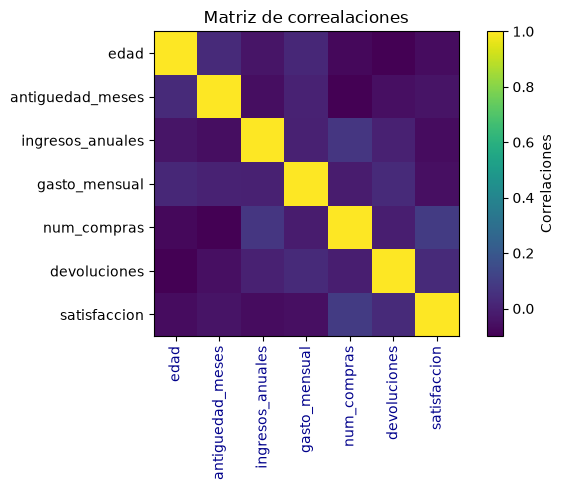

In [136]:
# TODO: representa la matriz de correlaciones con plt.imshow()
plt.figure(figsize=(7,5))
plt.imshow(correlaciones)
plt.xticks(range(len(correlaciones.columns)), correlaciones.columns, rotation=90, color="darkBlue")
plt.yticks(range(len(correlaciones.columns)), correlaciones.columns)
plt.colorbar(label="Correlaciones")
plt.title("Matriz de correalaciones")
plt.tight_layout()
plt.show()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. 
2. 
3. 

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [154]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas
df.groupby("compra_proximo_mes")["gasto_mensual"].agg(Numero_clientes="count",
    Gasto_medio="mean", 
    Mediana="median",
    Desviacion_estandar="std")


,Numero_clientes,Gasto_medio,Mediana,Desviacion_estandar
compra_proximo_mes,,,,
No,245,64.589469,59.28,33.693480
Sí,152,76.342368,66.50,45.534042


### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?  El de Sí
2. ¿Y mayor mediana? El de Sí
3. ¿Las diferencias parecen grandes o pequeñas? Pequeñas
4. ¿La media y la mediana cuentan exactamente la misma historia? Para nada, son muy diferentes


In [157]:
# INGRESOS ANUALES
df.groupby("compra_proximo_mes")["ingresos_anuales"].agg(Numero_clientes="count",
    Gasto_medio="mean",
    Mediana="median",
    Desviacion_estandar="std")


,Numero_clientes,Gasto_medio,Mediana,Desviacion_estandar
compra_proximo_mes,,,,
No,245,36457.790449,36999.62,13983.264281
Sí,151,36413.548411,36715.09,14910.598296


In [158]:
# NIVEL DE FIDELIDAD
df.groupby("nivel_fidelidad")["ingresos_anuales"].agg(Numero_clientes="count",
    Gasto_medio="mean",
    Mediana="median",
    Desviacion_estandar="std")


,Numero_clientes,Gasto_medio,Mediana,Desviacion_estandar
nivel_fidelidad,,,,
Bronce,162,36409.247963,37028.050,13261.941850
Oro,83,35921.890843,36831.090,14873.491333
Plata,103,37097.991068,37994.140,14716.674654
Platino,48,36035.339167,34151.525,16266.443749


# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

Text(0, 0.5, 'Gasto mensual')

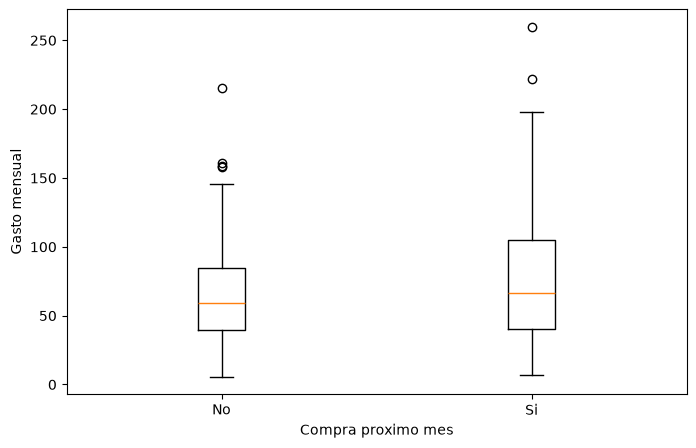

In [161]:
# TODO: crea grupo_no y grupo_si

grupo_no = df.loc[df["compra_proximo_mes"]=="No", "gasto_mensual"].dropna()
grupo_si = df.loc[df["compra_proximo_mes"]=="Sí", "gasto_mensual"].dropna()



# TODO: representa ambos grupos mediante un boxplot

plt.figure(figsize=(8,5))
plt.boxplot([grupo_no, grupo_si], tick_labels=["No", "Si"])
plt.xlabel("Compra proximo mes")
plt.ylabel("Gasto mensual")



### Interpreta

1. ¿Qué grupo presenta una mediana mayor? El grupo Sí (ligeramente superior)
2. ¿Cuál parece tener mayor dispersión? El grupo Sí, la altura de su caja (rango intercuartílico) como la distancia entre sus bigotes son más amplias.
3. ¿Existen outliers en ambos? Sí, ambos grupos muestran valores atípicos superiores (puntos aislados por encima del bigote máximo), aunque el grupo "Sí" alcanza valores más extremos (hasta 260).
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`? 

Sí, confirma visualmente lo mismo que mostraban los estadísticos agrupados: los clientes que vuelven a comprar el mes siguiente tienden a tener un gasto mensual promedio y mediano superior, además de una mayor variabilidad en sus importes.


# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [162]:
# TODO: tabla de contingencia con frecuencias absolutas
frecuencias = pd.crosstab(df["nivel_fidelidad"],df["compra_proximo_mes"])
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [163]:
# TODO: tabla normalizada por filas

frecuencias = pd.crosstab(df["nivel_fidelidad"],df["compra_proximo_mes"], normalize="index")
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [164]:
# TODO: muestra las proporciones como porcentajes
(frecuencias * 100).round(2) 

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran? Bronce
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran? Platino
3. ¿Coinciden necesariamente ambas respuestas? No, Bornce tiene más clientes en total, entonces acumula más compras en volumen aunque su tasa de conversión sea la más baja
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?
Porque permiten comparar el comportamiento real de cada grupo en igualdad de condiciones, evitando que el tamaño total de cada categoría distorsione la interpretación


# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

La conclusión del no es correcta, ya que está confundiendo **asociación** estadística con una relación de **causalidad**. 
Que los clientes de nivel Platino compren con mayor frecuencia no demuestra que subir de categoría provoque directamente la compra. 
Realmente, existen **variables adicionales** que explican este comportamiento, como los ingresos anuales, el historial previo de compras o el hábito de gasto del cliente... Para poder afirmar que cambiar de nivel genera un aumento real en las ventas, necesitaríamos **evidencia** experimental, no solo datos observacionales.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

--- Estadística descriptiva ---
       ingresos_anuales  gasto_mensual
count        393.000000     393.000000
mean       36538.187277      69.024122
std        14266.841244      39.133394
min         9000.000000       5.770000
25%        26190.310000      39.670000
50%        36831.090000      61.010000
75%        45879.100000      90.150000
max        82925.370000     260.000000


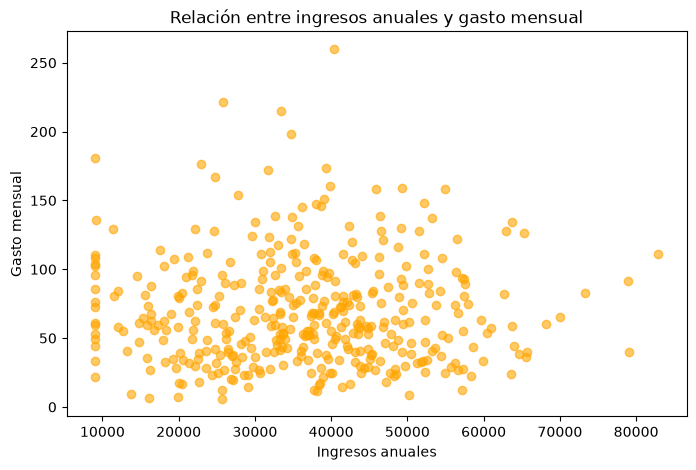


Coeficiente de correlación de Pearson: -0.000


In [165]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada

#1. selección de variables
datos_hipotesis = df[["ingresos_anuales", "gasto_mensual"]].dropna()

#2. estadística descriptiva

print("--- Estadística descriptiva ---")
print(datos_hipotesis.describe())
#3. visualización adecuada

plt.figure(figsize=(8, 5))
plt.scatter(datos_hipotesis["ingresos_anuales"], datos_hipotesis["gasto_mensual"], alpha=0.6, color="orange")
plt.title("Relación entre ingresos anuales y gasto mensual")
plt.xlabel("Ingresos anuales")
plt.ylabel("Gasto mensual")
plt.show()

#4. correlación si procede

correlacion = datos_hipotesis["ingresos_anuales"].corr(datos_hipotesis["gasto_mensual"])
print(f"\nCoeficiente de correlación de Pearson: {correlacion:.3f}")
#5. interpretación.

#
#
#

Al analizar la relación entre los ingresos anuales y el gasto mensual sobre los registros completos, observamos mediante el gráfico de dispersión cómo se distribuyen los clientes a lo largo de ambos ejes. El coeficiente de correlación de Pearson nos indica el grado y sentido de esta relación lineal (si es cercano a 1 habrá una relación positiva fuerte; si es cercano a 0, la relación lineal será débil o inexistente). En función del valor obtenido y de la nube de puntos observada, podemos comprobar si los ingresos anuales explican por sí solos el volumen de gasto mensual del cliente o si intervienen otros hábitos de consumo más relevantes.

### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

**Respuesta:**  
Escribe aquí.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [170]:
# TODO: comparación numérica
vars_num = ["edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones", "satisfaccion"]

# Estadísticas descriptivas
resumen_num = df.groupby("compra_proximo_mes")[vars_num].agg(["mean", "median"]).round(2)
display(resumen_num.T)

compra_proximo_mes             No        Sí
edad             mean       47.81     44.15
                 median     47.50     44.00
antiguedad_meses mean       59.47     60.46
                 median     59.00     60.50
ingresos_anuales mean    36457.79  36413.55
                 median  36999.62  36715.09
gasto_mensual    mean       64.59     76.34
                 median     59.28     66.50
num_compras      mean        8.15      8.35
                 median      8.00      8.00
devoluciones     mean        1.29      1.12
                 median      1.00      1.00
satisfaccion     mean        3.28      3.40
                 median      3.00      3.00

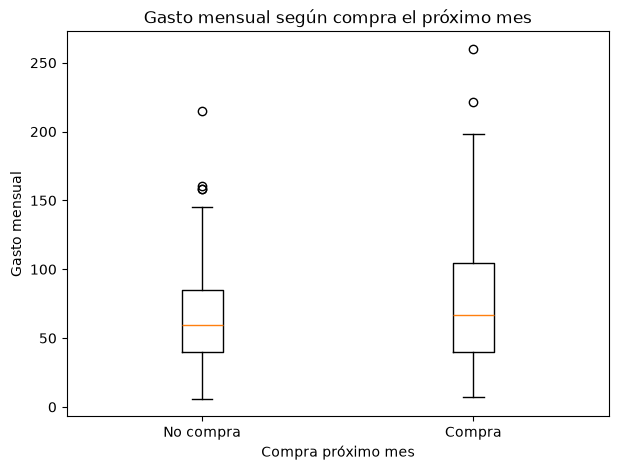

In [171]:
# TODO: primera visualización

gasto_no = df.loc[df["compra_proximo_mes"] == 0, "gasto_mensual"].dropna()
gasto_si = df.loc[df["compra_proximo_mes"] == 1, "gasto_mensual"].dropna()

plt.figure(figsize=(7, 5))
plt.boxplot(
    [
        df.loc[df["compra_proximo_mes"] == "No", "gasto_mensual"].dropna(),
        df.loc[df["compra_proximo_mes"] == "Sí", "gasto_mensual"].dropna()
    ],
    tick_labels=["No compra", "Compra"]
)
plt.title("Gasto mensual según compra el próximo mes")
plt.xlabel("Compra próximo mes")
plt.ylabel("Gasto mensual")
plt.show()


In [172]:
# TODO: comparación categórica y tabla de proporciones
tabla_abs = pd.crosstab(df["nivel_fidelidad"], df["compra_proximo_mes"])
tabla_prop = pd.crosstab(df["nivel_fidelidad"], df["compra_proximo_mes"], normalize="index").round(3) * 100

print("Conteo absoluto por nivel de fidelidad ")
display(tabla_abs)
print()
print("Porcentaje de compra (%) dentro de cada nivel ")
display(tabla_prop)

Conteo absoluto por nivel de fidelidad 


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31



Porcentaje de compra (%) dentro de cada nivel 


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.1,30.9
Oro,62.7,37.3
Plata,60.0,40.0
Platino,38.0,62.0


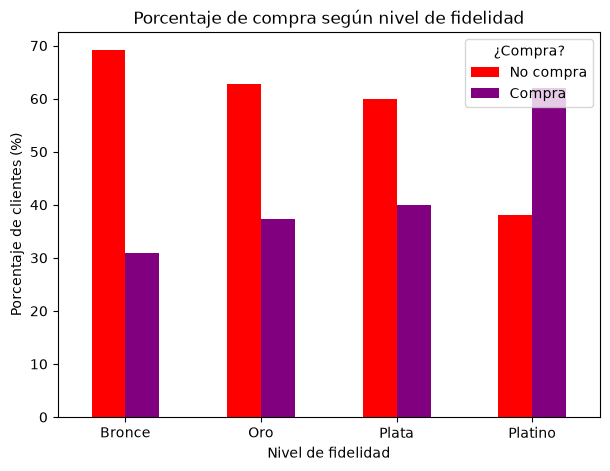

In [175]:
# TODO: segunda visualización

tabla_prop.plot(kind="bar", rot=0, figsize=(7, 5), color=["red", "purple"])
plt.title("Porcentaje de compra según nivel de fidelidad")
plt.xlabel("Nivel de fidelidad")
plt.ylabel("Porcentaje de clientes (%)")
plt.legend(["No compra", "Compra"], title="¿Compra?")
plt.show()

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**  
**Lo que observamos en el dataset:**
- **Gasto mensual y edad:** Las mayores diferencias numéricas están en el gasto mensual y la edad. Los clientes que sí compran el mes siguiente gastan bastante más de media (76,34 frente a 64,59; mediana de 66,50 frente a 59,28) y muestran una dispersión más alta en sus importes. Además, suelen ser algo más jóvenes (mediana de 44 años frente a 47,5 en los que no compran).
- **Nivel de fidelidad:** Se aprecia una diferencia clara en la tasa de compra según la categoría. Mientras que en el nivel Bronce solo compra el 30,9 %, el porcentaje sube en Oro (37,3 %) y Plata (40,0 %), disparándose hasta el 62,0 % en los clientes Platino (el único grupo donde son mayoría los que compran).
- **Variables muy similares:** El resto de métricas apenas cambian entre ambos grupos; los ingresos anuales (~36.400), la antigüedad (~60 meses), el número de compras históricas (mediana de 8), las devoluciones (mediana de 1) y la satisfacción (mediana de 3) son prácticamente iguales.

**Lo que no podemos concluir a partir de estos datos:**
- **Relaciones de causalidad:** Que los clientes de nivel Platino o con mayor gasto mensual compren más no significa que subir de nivel a un cliente o darle un cupón vaya a provocar automáticamente que compre el mes siguiente (asociación no implica causalidad).
- **Factores externos o futuros:** No sabemos si la decisión de compra está influida por variables que no están en la tabla, como campañas de marketing específicas, descuentos activos, estacionalidad o cambios recientes en la situación económica del cliente.

# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

### Hallazgo 1
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 2
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 3
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 4
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 5
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

Escribe aquí.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`